<a href="https://colab.research.google.com/github/bogomdanalnur135-coder/NU-/blob/main/SAA_AlPU_ML_FairComparison_1000vs15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SAA Al/PU Interfacial Strength — ML Comparison Study v2 (CORRECTED)
Reference article: Bakhbergen et al., Advanced Materials Interfaces, 2026
DOI: 10.1002/admi.202500916

Paste each "# ===== CELL N =====" block into its own Google Colab cell, in
order. Cell 2 needs two files uploaded:
  1) dataset_SAA_AlPU_1000_v2.xlsx   (from the corrected generator, sheet
     'SAA Dataset') -- 1000 synthetic rows.
  2) dataset_SAA_AlPU_15_real.xlsx   (sheet 'Real Dataset') -- the real
     15 samples (S1-S15) from Table 1 of the paper, Contact angle already
     merged in. This replaces the old rsm_experimental_runs.xlsx +
     in-code contact_angle_map dict: the real data now lives entirely in
     its own file, uploaded the same way as the synthetic 1000-row file,
     nothing hardcoded inside the script anymore.

=====================================================================
WHAT CHANGED vs the first version of this script, and WHY
=====================================================================

1. FAIR "1000 vs 15" COMPARISON (the main fix).
   The old script cross-validated dataset A (1000 synthetic rows) with
   KFold(10) and dataset C (15 real rows) with LeaveOneOut, then compared
   the two MAPE numbers directly. That is not a valid test of "does more
   data help" -- it compares two different validation *protocols* on two
   different *data-generating processes* (noiseless synthetic surface vs.
   real noisy measurements), which is a confound, not a sample-size effect.

   This version instead holds out 3 of the 15 real samples (S4, S6, S11 --
   chosen to span low/medium/high SLSS and different design corners) as a
   FIXED test set that no training variant ever touches. Models are trained
   separately on dataset A (1000 synthetic), dataset B (synthetic + the
   remaining 12 real samples merged in), and dataset C (those same 12 real
   samples alone) -- then ALL THREE are scored on the identical 3 held-out
   real samples. This is the only way to honestly claim "more data
   generalizes better to real measurements."

2. LEARNING CURVE.
   Beyond the single A/B/C comparison, a learning curve is built: train on
   random subsets of the synthetic pool of increasing size (12, 25, 50, 100,
   250, 500, 1000 rows), always testing on the same 3 real hold-out samples.
   This is the standard ML way to demonstrate a genuine sample-size effect,
   and is much more convincing evidence for a review/video than a single
   number.

3. NO DATA LEAKAGE INTO THE HOLD-OUT SET.
   build_dataset_B() now merges in only the 12 real TRAINING samples, never
   the 3 held-out test samples. In the original script all 15 real rows
   were merged into dataset B, which would have let the "test" samples leak
   into training data B -- making any hold-out evaluation meaningless.

4. FEATURES -- THREE SETS, EACH LABELED FOR WHAT IT ACTUALLY IS.
   The paper's ML models never use contact angle as an input (Section 2.6
   / Table 4): the "SAA only" set is concentration+current+time, and the
   AFM-augmented sets add Ra (profilometer roughness) + RMS + surface area
   + skew from AFM scans (Table S1, Supporting Information -- not available
   here). This script uses three feature sets:
     'saa_only'       -> concentration, current, time
                          (matches the paper's base ML set exactly)
     'saa_roughness'  -> + Roughness (Ra) only
                          (simplified, PARTIAL analogue of the paper's
                          AFM-augmented experiment -- RMS/surface area/skew
                          are not available -- don't present this as
                          reproducing Table 4)
     'saa_surf'       -> + Roughness (Ra) + Contact angle
                          (the ORIGINAL project spec's "surface features"
                          set -- this is the authors' OWN extension, the
                          paper's ML models never use contact angle as an
                          input at all, so label this clearly as your own
                          addition in the write-up, not a paper result)
   All three are evaluated identically below (CV diagnostics, fair
   hold-out comparison, learning curve) so you can see whether adding
   roughness / contact angle changes the sample-size conclusion.

5. MODEL HYPERPARAMETERS.
   Table 2 in the paper only specifies hyperparameters for DT, RF, ET, GB,
   AB. Bagging, SVR and KNN are not listed there, implying sklearn defaults
   were used. The old script set BaggingRegressor(n_estimators=100) with no
   basis in the paper; this version uses BaggingRegressor() (sklearn
   default n_estimators=10).

6. HONEST FIGURE LABELS.
   The old script's plots were captioned "Fig. 3/4/5/10 style" as if
   reproducing specific numbered figures from the paper. Several of those
   labels didn't match the paper's actual figure content/numbering (e.g.
   the real Fig. 7 is the ANOVA Pareto chart, not Fig. 5; the real Fig. 10
   is the ML MAPE bar chart, not a distributions histogram). This version
   captions each plot for what it actually is, and separately notes where
   it is inspired by / comparable to a specific paper figure.

7. PARETO / IMPORTANCE CHART.
   Switched from raw RandomForest impurity importance (biased, and the
   `permutation_importance` import was unused dead code in v1) to proper
   permutation importance, and the chart is captioned as an ML-based proxy
   for variable importance -- NOT the paper's Minitab ANOVA standardized
   effects (Fig. 7), which used a different statistical method entirely.
"""

In [1]:
# ===== CELL 1: install & imports =====================================
get_ipython().system('pip install -q openpyxl scikit-learn scipy pandas numpy matplotlib seaborn')

import io
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor,
    BaggingRegressor, GradientBoostingRegressor, AdaBoostRegressor
)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import LeaveOneOut, KFold, cross_val_predict
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
from sklearn.inspection import permutation_importance

print('Libraries loaded')

Libraries loaded


In [2]:
# ===== CELL 2: upload the two datasets =================================
# Both files are now plain, self-contained tables -- no hardcoded data and
# no in-code dictionaries. Upload:
#   1) dataset_SAA_AlPU_1000_v2.xlsx  (sheet 'SAA Dataset')      -- 1000 synthetic rows
#   2) dataset_SAA_AlPU_15_real.xlsx  (sheet 'Real Dataset')     -- 15 real rows (S1-S15),
#      already includes Contact angle (no separate dict/merge step needed anymore).
#      S0 (untreated reference) sits on its own sheet in that file and is
#      loaded separately below -- it is excluded from ML, exactly as in the
#      paper ("The results from 15 experiments were included in the model").
from google.colab import files

print('Upload dataset_SAA_AlPU_1000_v2.xlsx (corrected synthetic generator output)')
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df_synthetic = pd.read_excel(io.BytesIO(uploaded[filename]), sheet_name='SAA Dataset')
print(f'Synthetic dataset loaded: {len(df_synthetic)} rows, columns: {df_synthetic.columns.tolist()}')

print('\nUpload dataset_SAA_AlPU_15_real.xlsx (real Table 1 data, 15 samples used for ML)')
uploaded_real = files.upload()
real_filename = list(uploaded_real.keys())[0]
df_article_15 = pd.read_excel(io.BytesIO(uploaded_real[real_filename]), sheet_name='Real Dataset')
df_s0 = pd.read_excel(io.BytesIO(uploaded_real[real_filename]), sheet_name='S0_untreated_reference')
df_article_all = pd.concat([df_s0, df_article_15], ignore_index=True)

print(f'Real experimental data loaded: {len(df_article_15)} rows for ML (S1-S15)')
print(f'                               {len(df_article_all)} rows incl. untreated S0 (for context plots only)')

Upload dataset_SAA_AlPU_1000_v2.xlsx (corrected synthetic generator output)


Saving dataset_SAA_AlPU_1000_v2.xlsx to dataset_SAA_AlPU_1000_v2.xlsx
Synthetic dataset loaded: 1000 rows, columns: ['Sample ID', 'Concentration (M)', 'Current (A)', 'Time (min)', 'Roughness (nm)', 'Contact angle (°)', 'SLSS (MPa)']

Upload dataset_SAA_AlPU_15_real.xlsx (real Table 1 data, 15 samples used for ML)


Saving dataset_SAA_AlPU_15_real.xlsx to dataset_SAA_AlPU_15_real.xlsx
Real experimental data loaded: 15 rows for ML (S1-S15)
                               16 rows incl. untreated S0 (for context plots only)


In [3]:
# ===== CELL 3: sanity check of the real dataset =========================
df_article_15[['Sample', 'Concentration (M)', 'Current (A)', 'Time (min)',
               'Roughness (nm)', 'Contact angle (°)', 'SLSS (MPa)']]

,Sample,Concentration (M),Current (A),Time (min),Roughness (nm),Contact angle (°),SLSS (MPa)
0,S1,0.5,0.5,15.0,155.73,73.50,2.92
1,S2,0.5,0.5,45.0,181.73,45.17,2.92
2,S3,0.5,1.5,15.0,257.83,24.13,2.58
3,S4,0.5,1.5,45.0,167.23,90.77,3.26
4,S5,0.2,1.0,30.0,255.63,65.80,2.22
5,S6,1.0,0.2,30.0,133.60,88.87,1.65
6,S7,1.0,1.0,5.5,200.06,20.33,2.56
7,S8,1.0,1.0,30.0,119.69,17.77,2.47
8,S9,1.0,1.0,54.5,175.13,69.10,2.66
9,S10,1.0,1.8,30.0,284.14,89.63,2.52


In [4]:
# ===== CELL 4: held-out REAL test set (critical fix) =====================
# Fixed, hand-picked hold-out spanning low/high SLSS and different CCD
# design regions (S4 = factorial corner w/ highest SLSS, S6 = axial point
# w/ lowest SLSS, S11 = axial point on the concentration axis). None of
# these 3 rows are used anywhere in training, synthetic-mixing, or model
# fitting for ANY of datasets A/B/C below.
HOLD_OUT_SAMPLES = ['S4', 'S6', 'S11']

df_test_real = df_article_15[df_article_15['Sample'].isin(HOLD_OUT_SAMPLES)].reset_index(drop=True)
df_train_real = df_article_15[~df_article_15['Sample'].isin(HOLD_OUT_SAMPLES)].reset_index(drop=True)

print(f'Held-out REAL test set ({len(df_test_real)} rows): {HOLD_OUT_SAMPLES}')
print(f'Real training pool ({len(df_train_real)} rows): {sorted(df_train_real["Sample"].tolist())}')
df_test_real[['Sample', 'Concentration (M)', 'Current (A)', 'Time (min)', 'SLSS (MPa)']]

Held-out REAL test set (3 rows): ['S4', 'S6', 'S11']
Real training pool (12 rows): ['S1', 'S10', 'S12', 'S13', 'S14', 'S15', 'S2', 'S3', 'S5', 'S7', 'S8', 'S9']


,Sample,Concentration (M),Current (A),Time (min),SLSS (MPa)
0,S4,0.5,1.5,45.0,3.26
1,S6,1.0,0.2,30.0,1.65
2,S11,1.8,1.0,30.0,2.08


In [5]:
# ===== CELL 5: smart merge -> dataset B (uses ONLY the 12 real TRAIN rows) =
def build_dataset_B(df_synth, df_exp, verbose=True):
    """
    Replace/insert real experimental rows into the synthetic dataset at the
    position closest to them in (Concentration, Current, Time) space.

    IMPORTANT: df_exp must be df_train_real, NOT df_article_15 -- otherwise
    the held-out test rows leak into the training data and Cell 8's
    hold-out evaluation becomes meaningless.
    """
    match_cols = ['Concentration (M)', 'Current (A)', 'Time (min)']
    synth_vals = df_synth[match_cols].values.astype(float)
    exp_vals = df_exp[match_cols].values.astype(float)

    col_ranges = synth_vals.max(axis=0) - synth_vals.min(axis=0)
    col_ranges[col_ranges == 0] = 1
    synth_norm = synth_vals / col_ranges
    exp_norm = exp_vals / col_ranges

    threshold = 0.15  # normalized-distance cutoff for "replace" vs "insert" (heuristic, not from the paper)

    df_result = df_synth.copy()
    df_result['_source'] = 'synthetic'
    df_result['_exp_label'] = ''

    log = []
    replaced_indices = set()
    exp_cols = [c for c in ['Concentration (M)', 'Current (A)', 'Time (min)',
                             'Roughness (nm)', 'Contact angle (°)', 'SLSS (MPa)']
                if c in df_exp.columns and c in df_result.columns]

    rows_to_insert = []
    for i, exp_row in df_exp.iterrows():
        sample_id = exp_row.get('Sample', f'Exp_{i}')
        dists = cdist(exp_norm[[i]], synth_norm, metric='euclidean')[0]
        available = [j for j in range(len(dists)) if j not in replaced_indices]
        if not available:
            available = list(range(len(dists)))
        best_idx = min(available, key=lambda j: dists[j])
        best_dist = dists[best_idx]

        if best_dist < threshold:
            for col in exp_cols:
                df_result.at[best_idx, col] = exp_row[col]
            df_result.at[best_idx, '_source'] = 'experimental'
            df_result.at[best_idx, '_exp_label'] = sample_id
            replaced_indices.add(best_idx)
            log.append({'Sample': sample_id, 'Operation': 'REPLACE',
                        'Position': best_idx, 'Distance': round(best_dist, 4)})
        else:
            exp_dict = {col: exp_row[col] for col in exp_cols}
            exp_dict['_source'] = 'experimental'
            exp_dict['_exp_label'] = sample_id
            for col in df_result.columns:
                if col not in exp_dict:
                    exp_dict[col] = df_result.at[best_idx, col]
            rows_to_insert.append((best_idx, exp_dict))
            log.append({'Sample': sample_id, 'Operation': 'INSERT',
                        'Position': best_idx, 'Distance': round(best_dist, 4)})

    if rows_to_insert:
        insert_df = pd.DataFrame([rd for _, rd in rows_to_insert])
        df_result = pd.concat([df_result, insert_df], ignore_index=True)
        df_result = df_result.sort_values(
            by=['Concentration (M)', 'Current (A)', 'Time (min)']
        ).reset_index(drop=True)

    return df_result, pd.DataFrame(log)


df_B_full, merge_log = build_dataset_B(df_synthetic, df_train_real)
print(f'Dataset B created: {len(df_B_full)} rows, '
      f'{(df_B_full["_source"] == "experimental").sum()} experimental (out of {len(df_train_real)} real train rows)')
print(merge_log.to_string(index=False))

Dataset B created: 1000 rows, 12 experimental (out of 12 real train rows)
Sample Operation  Position  Distance
    S1   REPLACE       232    0.0471
    S2   REPLACE       293    0.0238
    S3   REPLACE       637    0.0517
    S5   REPLACE       503    0.0496
    S7   REPLACE       940    0.0615
    S8   REPLACE         6    0.0704
    S9   REPLACE       911    0.0429
   S10   REPLACE       308    0.0715
   S12   REPLACE       760    0.0459
   S13   REPLACE       902    0.0580
   S14   REPLACE       924    0.0862
   S15   REPLACE        23    0.0695


In [6]:
# ===== CELL 6: final dataset definitions =================================
df_A = df_synthetic.copy()                                                  # 1000 synthetic rows
df_B = df_B_full.drop(columns=['_source', '_exp_label'], errors='ignore')   # synthetic + 12 real (merged)
df_C = df_train_real.copy()                                                 # 12 real rows only (training)
# df_test_real (3 rows) = the ONE fixed evaluation set used for all three below

print(f'Dataset A (synthetic):        {len(df_A)} rows')
print(f'Dataset B (mixed):            {len(df_B)} rows')
print(f'Dataset C (real, train-only): {len(df_C)} rows')
print(f'Held-out real test set:       {len(df_test_real)} rows')

Dataset A (synthetic):        1000 rows
Dataset B (mixed):            1000 rows
Dataset C (real, train-only): 12 rows
Held-out real test set:       3 rows


In [7]:
# ===== CELL 7: models =====================================================
# Hyperparameters follow Table 2 of the paper where specified (DT, RF, ET,
# GB, AB); BG/SVR/KNN are not listed there, so sklearn defaults are used.
def get_pipelines():
    base_models = {
        'DT': DecisionTreeRegressor(random_state=42),
        'RF': RandomForestRegressor(n_estimators=100, random_state=42),
        'ET': ExtraTreesRegressor(n_estimators=100, random_state=42),
        'BG': BaggingRegressor(random_state=42),  # default n_estimators=10 -- not specified in Table 2
        'GB': GradientBoostingRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42),
        'AB': AdaBoostRegressor(n_estimators=50, learning_rate=1, random_state=42),
        'SVR': SVR(kernel='rbf', C=1.0, epsilon=0.1),   # sklearn defaults -- not specified in Table 2
        'KNN': KNeighborsRegressor(n_neighbors=5),        # sklearn default -- not specified in Table 2
    }
    # Scaler INSIDE the pipeline -> fit only on training folds -> no leakage
    return {name: Pipeline([('scaler', MinMaxScaler()), ('model', m)]) for name, m in base_models.items()}


models_list = list(get_pipelines().keys())
print('Models:', models_list)

Models: ['DT', 'RF', 'ET', 'BG', 'GB', 'AB', 'SVR', 'KNN']


In [8]:
# ===== CELL 8: feature preparation ========================================
FEATURE_SETS = ('saa_only', 'saa_roughness', 'saa_surf')
FEATURE_SET_LABELS = {
    'saa_only':      'SAA only (matches paper)',
    'saa_roughness': '+ Roughness (partial AFM analogue)',
    'saa_surf':      '+ Roughness + Contact angle (own extension)',
}


def prepare_features(df, feature_set='saa_only'):
    """
    'saa_only'      -> Concentration, Current, Time. Matches the paper's
                        base ML feature set exactly (Section 2.6).
    'saa_roughness' -> + Roughness (Ra). A simplified, PARTIAL analogue of
                        the paper's AFM-augmented feature sets (which also
                        included RMS, surface area, skew from AFM scans --
                        not available here). Do not present this as
                        reproducing the paper's Table 4.
    'saa_surf'      -> + Roughness (Ra) + Contact angle. This is the
                        ORIGINAL project spec's "surface features" set --
                        it is the authors' OWN extension. The paper's ML
                        models never use contact angle as an input at all
                        (Table 4 only ever adds Ra/RMS/surface area/skew).
                        Label this as your own addition in any write-up,
                        not a result from the paper.
    """
    saa_cols = ['Concentration (M)', 'Current (A)', 'Time (min)']
    target = 'SLSS (MPa)'
    if feature_set == 'saa_only':
        cols = saa_cols
    elif feature_set == 'saa_roughness':
        cols = saa_cols + ['Roughness (nm)']
    elif feature_set == 'saa_surf':
        cols = saa_cols + ['Roughness (nm)', 'Contact angle (°)']
    else:
        raise ValueError(feature_set)
    sub = df[cols + [target]].dropna()
    X = sub[cols].values.astype(float)
    y = sub[target].values.astype(float)
    return X, y, cols

In [9]:
# ===== CELL 9: internal CV diagnostics (NOT the fair size comparison) ====
# These numbers use each dataset's OWN cross-validation split (KFold(10)
# for A/B, LeaveOneOut for C). They are useful diagnostics of in-sample fit
# quality, but because A/B are synthetic and C is real, comparing these
# numbers to each other directly does NOT isolate the effect of sample
# size (see Cell 10 for the fair comparison).
def evaluate_models_cv(df, feature_set='saa_only', cv_method='auto'):
    X, y, used_cols = prepare_features(df, feature_set)
    n = len(y)
    if cv_method == 'auto':
        cv = LeaveOneOut() if n <= 100 else KFold(n_splits=10, shuffle=True, random_state=42)
    elif cv_method == 'loo':
        cv = LeaveOneOut()
    else:
        cv = KFold(n_splits=10, shuffle=True, random_state=42)

    results = {}
    for name, pipe in get_pipelines().items():
        y_pred = cross_val_predict(pipe, X, y, cv=cv)
        results[name] = {
            'MAPE': round(mean_absolute_percentage_error(y, y_pred), 4),
            'RMSE': round(np.sqrt(mean_squared_error(y, y_pred)), 4),
        }
    return pd.DataFrame(results).T, used_cols


print('Internal CV diagnostics (own-dataset CV, NOT the fair comparison):')
cv_results = {}  # cv_results[feature_set] = (res_A, res_B, res_C)
for fs in FEATURE_SETS:
    res_A, _ = evaluate_models_cv(df_A, fs)
    res_B, _ = evaluate_models_cv(df_B, fs)
    res_C, _ = evaluate_models_cv(df_C, fs, cv_method='loo')
    cv_results[fs] = (res_A, res_B, res_C)
    print(f'\n--- Feature set: {fs} ({FEATURE_SET_LABELS[fs]}) ---')
    print('A: Synthetic (KFold 10):\n', res_A)
    print('B: Mixed (KFold 10):\n', res_B)
    print('C: Real, 12 rows (LOO):\n', res_C)

# Convenience aliases for the paper-matching feature set (used by later cells
# that only need one feature set, e.g. the permutation-importance chart)
res_A_saa, res_B_saa, res_C_saa = cv_results['saa_only']

Internal CV diagnostics (own-dataset CV, NOT the fair comparison):

--- Feature set: saa_only (SAA only (matches paper)) ---
A: Synthetic (KFold 10):
        MAPE    RMSE
DT   0.0811  0.2473
RF   0.0635  0.1944
ET   0.0647  0.1959
BG   0.0657  0.2007
GB   0.0633  0.1933
AB   0.0665  0.2008
SVR  0.0619  0.1884
KNN  0.0673  0.2048
B: Mixed (KFold 10):
        MAPE    RMSE
DT   0.0845  0.2562
RF   0.0639  0.1949
ET   0.0654  0.1971
BG   0.0668  0.2038
GB   0.0637  0.1947
AB   0.0662  0.2005
SVR  0.0622  0.1896
KNN  0.0678  0.2056
C: Real, 12 rows (LOO):
        MAPE    RMSE
DT   0.0458  0.1532
RF   0.0848  0.2292
ET   0.0802  0.2333
BG   0.0890  0.2458
GB   0.0506  0.1641
AB   0.0678  0.2200
SVR  0.1273  0.3499
KNN  0.1323  0.3546

--- Feature set: saa_roughness (+ Roughness (partial AFM analogue)) ---
A: Synthetic (KFold 10):
        MAPE    RMSE
DT   0.0806  0.2446
RF   0.0631  0.1934
ET   0.0640  0.1942
BG   0.0644  0.1979
GB   0.0633  0.1935
AB   0.0655  0.1979
SVR  0.0634  0.1925
KNN

Fair comparison: fit on A / B / C, score on the SAME held-out real samples ['S4', 'S6', 'S11']

--- Feature set: saa_only (SAA only (matches paper)) ---
    A: Synthetic (1000)         B: Mixed         C: Real (12 train)        
                   MAPE    RMSE     MAPE    RMSE               MAPE    RMSE
DT               0.2078  0.4355   0.2078  0.4355             0.3660  0.8292
RF               0.1393  0.3543   0.1422  0.3530             0.3181  0.7307
ET               0.1422  0.3581   0.1450  0.3671             0.2597  0.6650
BG               0.1701  0.3914   0.1440  0.3544             0.2996  0.6849
GB               0.1367  0.3488   0.1545  0.3862             0.3375  0.7658
AB               0.1588  0.3853   0.1710  0.4033             0.3055  0.6873
SVR              0.1521  0.3377   0.1536  0.3420             0.2861  0.7240
KNN              0.1438  0.3653   0.1438  0.3653             0.2632  0.6660

--- Feature set: saa_roughness (+ Roughness (partial AFM analogue)) ---
    A: Synthet

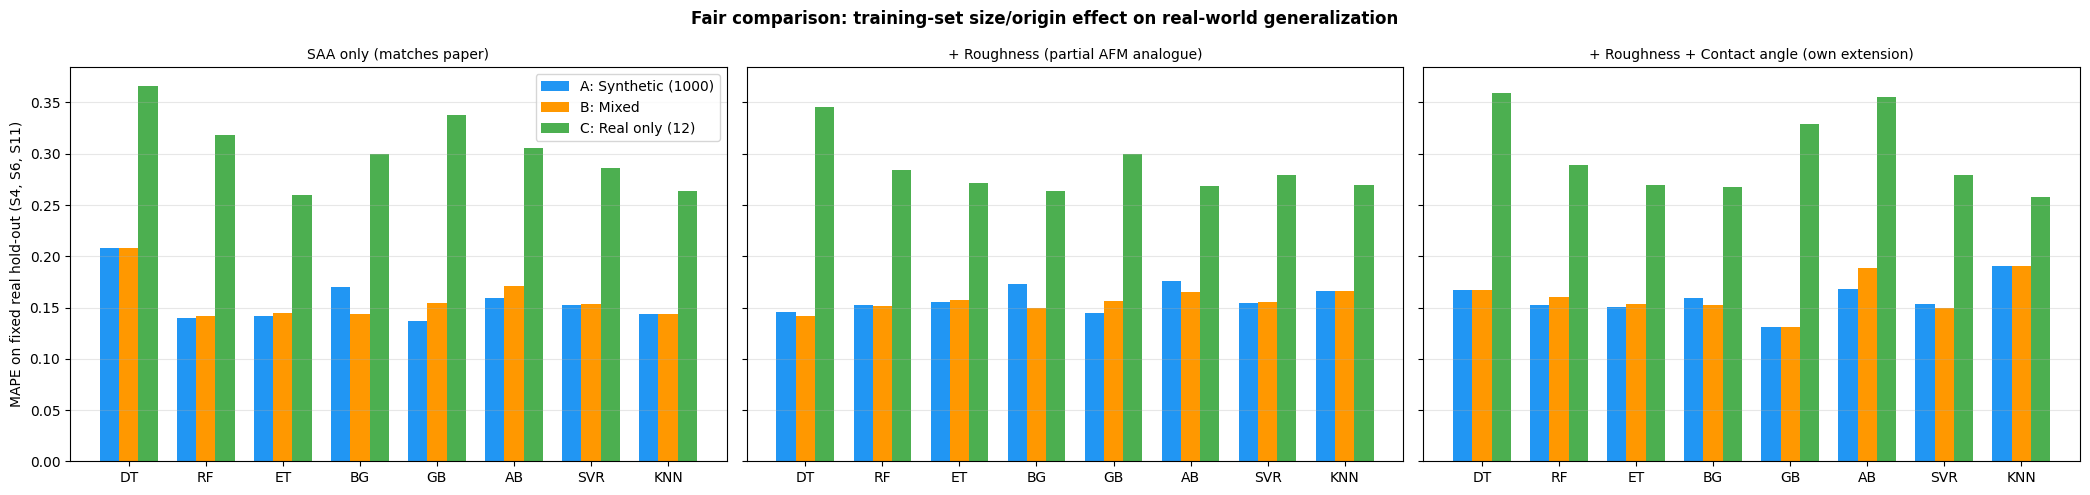

In [10]:
# ===== CELL 10: THE FAIR comparison -- fit on A/B/C, score on SAME real hold-out
def fit_and_score_on_holdout(df_train, df_test, feature_set='saa_only'):
    X_train, y_train, cols = prepare_features(df_train, feature_set)
    X_test, y_test, _ = prepare_features(df_test, feature_set)
    results = {}
    for name, pipe in get_pipelines().items():
        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)
        results[name] = {
            'MAPE': round(mean_absolute_percentage_error(y_test, y_pred), 4),
            'RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred)), 4),
        }
    return pd.DataFrame(results).T, cols


print(f'Fair comparison: fit on A / B / C, score on the SAME held-out real samples {HOLD_OUT_SAMPLES}')
holdout_results = {}  # holdout_results[feature_set] = (holdout_A, holdout_B, holdout_C)
for fs in FEATURE_SETS:
    h_A, _ = fit_and_score_on_holdout(df_A, df_test_real, fs)
    h_B, _ = fit_and_score_on_holdout(df_B, df_test_real, fs)
    h_C, _ = fit_and_score_on_holdout(df_C, df_test_real, fs)
    holdout_results[fs] = (h_A, h_B, h_C)

    comparison_holdout = pd.DataFrame({
        ('A: Synthetic (1000)', 'MAPE'): h_A['MAPE'], ('A: Synthetic (1000)', 'RMSE'): h_A['RMSE'],
        ('B: Mixed',            'MAPE'): h_B['MAPE'], ('B: Mixed',            'RMSE'): h_B['RMSE'],
        ('C: Real (12 train)',  'MAPE'): h_C['MAPE'], ('C: Real (12 train)',  'RMSE'): h_C['RMSE'],
    })
    comparison_holdout.columns = pd.MultiIndex.from_tuples(comparison_holdout.columns)
    print(f'\n--- Feature set: {fs} ({FEATURE_SET_LABELS[fs]}) ---')
    print(comparison_holdout.to_string())

# Convenience aliases for the paper-matching feature set (used in the Excel export)
holdout_A, holdout_B, holdout_C = holdout_results['saa_only']

fig, axes = plt.subplots(1, len(FEATURE_SETS), figsize=(7 * len(FEATURE_SETS), 5), sharey=True)
x = np.arange(len(models_list))
width = 0.25
for ax, fs in zip(axes, FEATURE_SETS):
    h_A, h_B, h_C = holdout_results[fs]
    ax.bar(x - width, h_A.loc[models_list, 'MAPE'], width, label='A: Synthetic (1000)', color='#2196F3')
    ax.bar(x,         h_B.loc[models_list, 'MAPE'], width, label='B: Mixed',            color='#FF9800')
    ax.bar(x + width, h_C.loc[models_list, 'MAPE'], width, label='C: Real only (12)',   color='#4CAF50')
    ax.set_xticks(x)
    ax.set_xticklabels(models_list)
    ax.set_title(FEATURE_SET_LABELS[fs], fontsize=10)
    ax.grid(axis='y', alpha=0.3)
axes[0].set_ylabel('MAPE on fixed real hold-out (S4, S6, S11)')
axes[0].legend()
fig.suptitle('Fair comparison: training-set size/origin effect on real-world generalization', fontweight='bold')
plt.tight_layout()
plt.savefig('holdout_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


--- Feature set: saa_only (SAA only (matches paper)) ---
   Model     N      mean       std
0     ET    12  0.231995  0.042081
1     ET    25  0.224004  0.022506
2     ET    50  0.191400  0.026961
3     ET   100  0.189588  0.023892
4     ET   250  0.162655  0.018475
5     ET   500  0.149405  0.019039
6     ET  1000  0.142597  0.000434
7     RF    12  0.234970  0.038449
8     RF    25  0.220332  0.032596
9     RF    50  0.203845  0.021238
10    RF   100  0.182006  0.025393
11    RF   250  0.164481  0.014150
12    RF   500  0.152059  0.022084
13    RF  1000  0.145286  0.004464
14   SVR    12  0.228960  0.041344
15   SVR    25  0.219995  0.040126
16   SVR    50  0.171008  0.025905
17   SVR   100  0.169960  0.019814
18   SVR   250  0.145155  0.010479
19   SVR   500  0.155207  0.014358
20   SVR  1000  0.152080  0.000030

--- Feature set: saa_roughness (+ Roughness (partial AFM analogue)) ---
   Model     N      mean       std
0     ET    12  0.233781  0.041795
1     ET    25  0.222611  0.0

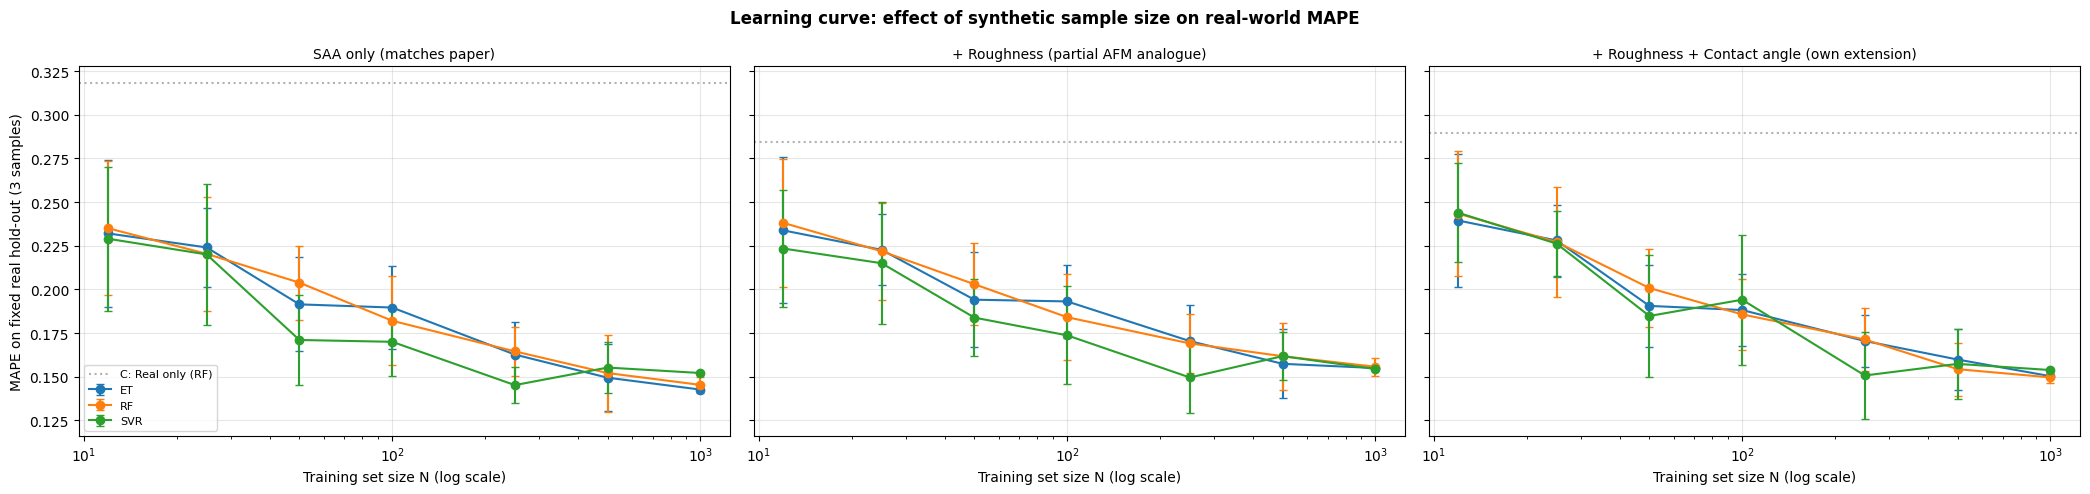

In [11]:
# ===== CELL 11: learning curve (does MORE synthetic data reduce real-world error?)
def learning_curve_on_real_holdout(df_pool, df_test, feature_set='saa_only',
                                    sizes=(12, 25, 50, 100, 250, 500, 1000),
                                    model_names=('RF', 'SVR', 'ET'), n_repeats=10, seed=42):
    X_test, y_test, _ = prepare_features(df_test, feature_set)
    rng = np.random.default_rng(seed)
    records = []
    pool_idx = np.arange(len(df_pool))
    for n in sizes:
        n = min(n, len(df_pool))
        for rep in range(n_repeats):
            sub_idx = rng.choice(pool_idx, size=n, replace=False)
            df_sub = df_pool.iloc[sub_idx]
            X_train, y_train, _ = prepare_features(df_sub, feature_set)
            for name, pipe in get_pipelines().items():
                if name not in model_names:
                    continue
                pipe.fit(X_train, y_train)
                y_pred = pipe.predict(X_test)
                records.append({'N': n, 'rep': rep, 'Model': name,
                                 'MAPE': mean_absolute_percentage_error(y_test, y_pred)})
    return pd.DataFrame(records)


lc_results = {}  # lc_results[feature_set] = (lc_df, lc_summary)
for fs in FEATURE_SETS:
    lc_df_fs = learning_curve_on_real_holdout(df_A, df_test_real, feature_set=fs)
    lc_summary_fs = lc_df_fs.groupby(['Model', 'N'])['MAPE'].agg(['mean', 'std']).reset_index()
    lc_results[fs] = (lc_df_fs, lc_summary_fs)
    print(f'\n--- Feature set: {fs} ({FEATURE_SET_LABELS[fs]}) ---')
    print(lc_summary_fs.to_string())

# Convenience aliases for the paper-matching feature set (used in the Excel export)
lc_df, lc_summary = lc_results['saa_only']

fig, axes = plt.subplots(1, len(FEATURE_SETS), figsize=(7 * len(FEATURE_SETS), 5), sharey=True)
for ax, fs in zip(axes, FEATURE_SETS):
    _, lc_summary_fs = lc_results[fs]
    _, _, h_C = holdout_results[fs]
    for name in lc_summary_fs['Model'].unique():
        sub = lc_summary_fs[lc_summary_fs['Model'] == name]
        ax.errorbar(sub['N'], sub['mean'], yerr=sub['std'], marker='o', capsize=3, label=name)
    # Overlay the single-point C (real-only) RF result for context
    ax.axhline(h_C.loc['RF', 'MAPE'], color='gray', linestyle=':', alpha=0.6, label='C: Real only (RF)')
    ax.set_xscale('log')
    ax.set_xlabel('Training set size N (log scale)')
    ax.set_title(FEATURE_SET_LABELS[fs], fontsize=10)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('MAPE on fixed real hold-out (3 samples)')
axes[0].legend(fontsize=8)
fig.suptitle('Learning curve: effect of synthetic sample size on real-world MAPE', fontweight='bold')
plt.tight_layout()
plt.savefig('learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()


--- Feature set: saa_only ---
  Concentration (M): 1.1317 +/- 0.0413
  Current (A): 0.3732 +/- 0.0141
  Time (min): 0.5035 +/- 0.0162

--- Feature set: saa_surf ---
  Concentration (M): 1.0781 +/- 0.0387
  Current (A): 0.2825 +/- 0.0132
  Time (min): 0.4619 +/- 0.0157
  Roughness (nm): 0.0663 +/- 0.0022
  Contact angle (°): 0.0916 +/- 0.0042


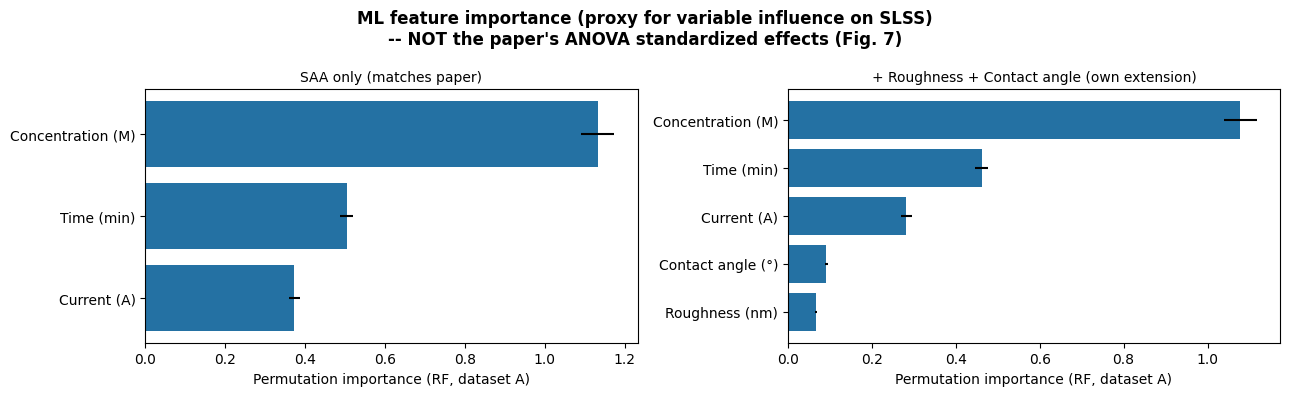

In [12]:
# ===== CELL 12: permutation-importance "Pareto-style" chart ==============
# NOTE: this is an ML feature-importance proxy (permutation importance on a
# Random Forest), not the paper's Fig. 7, which comes from Minitab ANOVA
# standardized effects on the RSM regression. Different method, don't
# caption this as reproducing Fig. 7 -- it's a complementary ML view.
# Shown for 'saa_only' (matches the paper's inputs) and 'saa_surf' (own
# extension with Roughness + Contact angle) side by side.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, fs in zip(axes, ['saa_only', 'saa_surf']):
    X_fi, y_fi, fi_cols = prepare_features(df_A, fs)
    scaler_fi = MinMaxScaler()
    X_fi_sc = scaler_fi.fit_transform(X_fi)
    rf_fi = RandomForestRegressor(n_estimators=200, random_state=42)
    rf_fi.fit(X_fi_sc, y_fi)
    perm = permutation_importance(rf_fi, X_fi_sc, y_fi, n_repeats=30, random_state=42)

    order = np.argsort(perm.importances_mean)
    ax.barh([fi_cols[i] for i in order], perm.importances_mean[order],
            xerr=perm.importances_std[order], color='#2471A3')
    ax.set_xlabel('Permutation importance (RF, dataset A)')
    ax.set_title(FEATURE_SET_LABELS[fs], fontsize=10)

    print(f'\n--- Feature set: {fs} ---')
    for c, m, s in zip(fi_cols, perm.importances_mean, perm.importances_std):
        print(f'  {c}: {m:.4f} +/- {s:.4f}')

fig.suptitle('ML feature importance (proxy for variable influence on SLSS)\n'
             "-- NOT the paper's ANOVA standardized effects (Fig. 7)", fontweight='bold')
plt.tight_layout()
plt.savefig('permutation_importance.png', dpi=150, bbox_inches='tight')
plt.show()

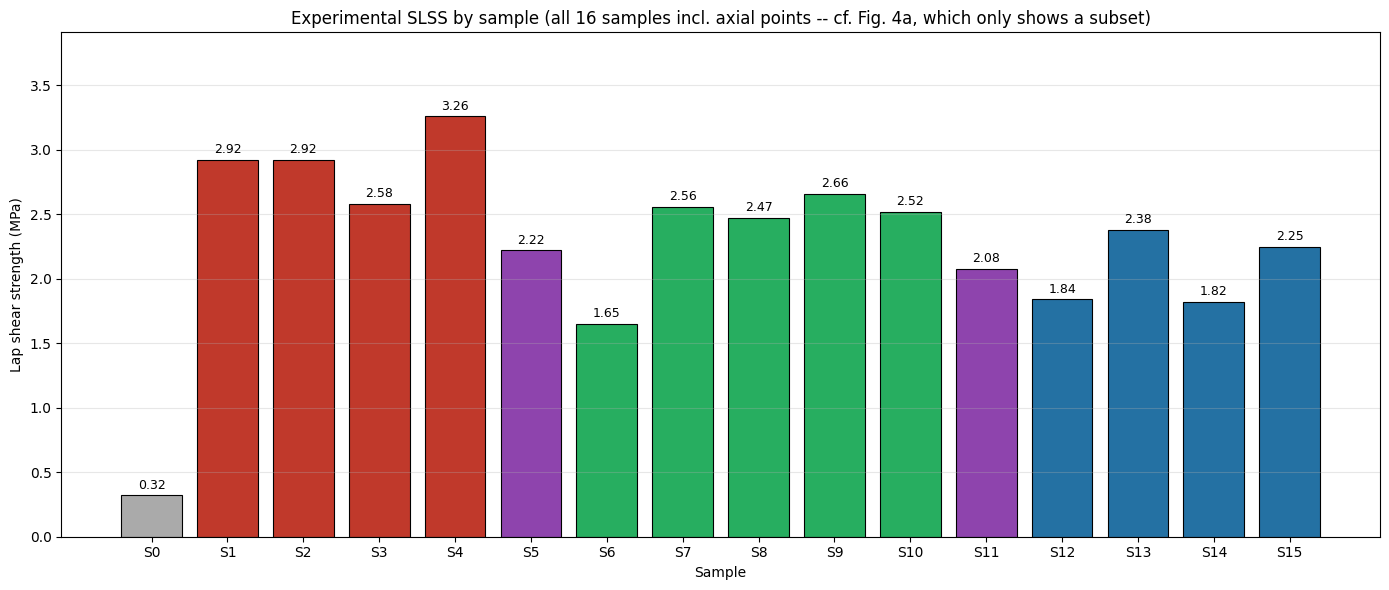

In [13]:
# ===== CELL 13: SLSS by real sample (for context, cf. Fig. 4a of the paper)
samples_plot = df_article_all[['Sample', 'Concentration (M)', 'Current (A)', 'Time (min)', 'SLSS (MPa)']].copy()


def get_color(row):
    conc = row['Concentration (M)']
    if conc == 0:
        return '#AAAAAA'
    if conc == 0.5:
        return '#C0392B'
    if conc == 1.0:
        return '#27AE60'
    if conc == 1.5:
        return '#2471A3'
    return '#8E44AD'  # axial points (0.2 / 1.8 M) -- not part of the paper's Fig. 4a subset


bar_colors = samples_plot.apply(get_color, axis=1)
fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.bar(samples_plot['Sample'], samples_plot['SLSS (MPa)'], color=bar_colors, edgecolor='black', linewidth=0.8)
ax.set_ylabel('Lap shear strength (MPa)')
ax.set_xlabel('Sample')
ax.set_title('Experimental SLSS by sample (all 16 samples incl. axial points -- cf. Fig. 4a, which only shows a subset)')
ax.set_ylim(0, samples_plot['SLSS (MPa)'].max() * 1.2)
ax.grid(axis='y', alpha=0.3)
for bar, val in zip(bars, samples_plot['SLSS (MPa)']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.03, f'{val:.2f}',
            ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig('slss_by_sample.png', dpi=150, bbox_inches='tight')
plt.show()

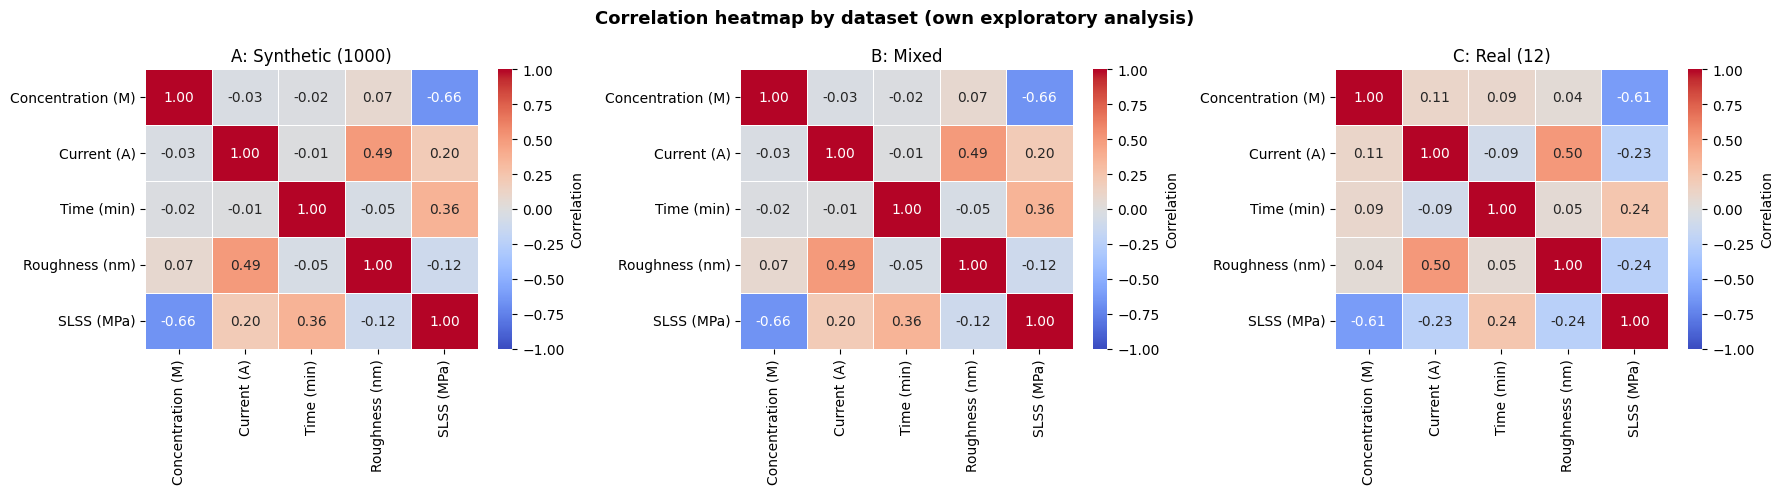

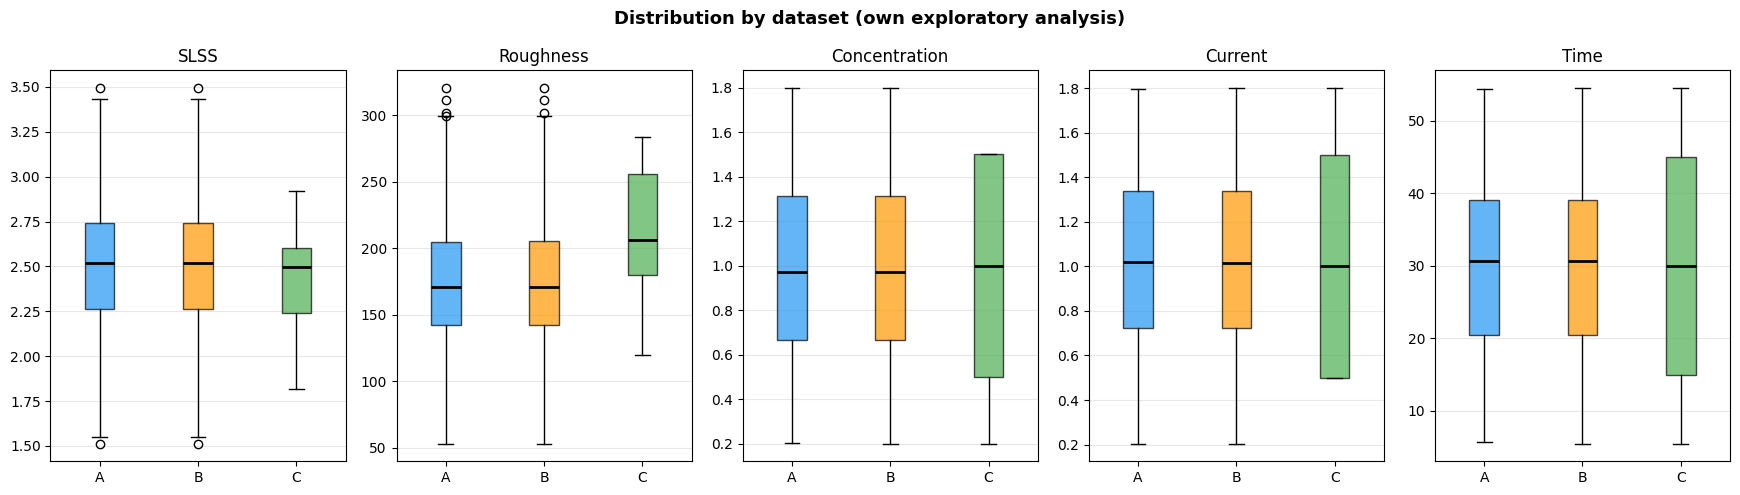

In [14]:
# ===== CELL 14: correlation heatmaps + box plots across A / B / C ========
corr_cols = ['Concentration (M)', 'Current (A)', 'Time (min)', 'Roughness (nm)', 'SLSS (MPa)']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Correlation heatmap by dataset (own exploratory analysis)', fontsize=13, fontweight='bold')
for ax, (df_corr, label) in zip(axes, [(df_A, 'A: Synthetic (1000)'), (df_B, 'B: Mixed'), (df_C, 'C: Real (12)')]):
    available = [c for c in corr_cols if c in df_corr.columns and df_corr[c].notna().all()]
    sns.heatmap(df_corr[available].corr(), annot=True, fmt='.2f', cmap='coolwarm',
                ax=ax, vmin=-1, vmax=1, linewidths=0.5, cbar_kws={'label': 'Correlation'})
    ax.set_title(label)
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

box_cols = ['SLSS (MPa)', 'Roughness (nm)', 'Concentration (M)', 'Current (A)', 'Time (min)']
fig, axes = plt.subplots(1, len(box_cols), figsize=(3.5 * len(box_cols), 5))
fig.suptitle('Distribution by dataset (own exploratory analysis)', fontsize=13, fontweight='bold')
for ax, feat in zip(axes, box_cols):
    data = [df_bp[feat].dropna().values for df_bp in [df_A, df_B, df_C]]
    bp = ax.boxplot(data, patch_artist=True, medianprops=dict(color='black', linewidth=2))
    for patch, color in zip(bp['boxes'], ['#2196F3', '#FF9800', '#4CAF50']):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_title(feat.split(' ')[0])
    ax.set_xticklabels(['A', 'B', 'C'])
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('boxplots_features.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
# ===== CELL 15: save everything to Excel + download ======================
output_file = 'ML_Comparison_Results_v2.xlsx'
with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    for fs in FEATURE_SETS:
        h_A, h_B, h_C = holdout_results[fs]
        comparison_fs = pd.DataFrame({
            ('A: Synthetic (1000)', 'MAPE'): h_A['MAPE'], ('A: Synthetic (1000)', 'RMSE'): h_A['RMSE'],
            ('B: Mixed',            'MAPE'): h_B['MAPE'], ('B: Mixed',            'RMSE'): h_B['RMSE'],
            ('C: Real (12 train)',  'MAPE'): h_C['MAPE'], ('C: Real (12 train)',  'RMSE'): h_C['RMSE'],
        })
        comparison_fs.columns = pd.MultiIndex.from_tuples(comparison_fs.columns)
        comparison_fs.to_excel(writer, sheet_name=f'Holdout_{fs}'[:31])

        _, lc_summary_fs = lc_results[fs]
        lc_summary_fs.to_excel(writer, sheet_name=f'LearnCurve_{fs}'[:31], index=False)

        res_A_fs, res_B_fs, res_C_fs = cv_results[fs]
        res_A_fs.to_excel(writer, sheet_name=f'CVdiag_A_{fs}'[:31])
        res_B_fs.to_excel(writer, sheet_name=f'CVdiag_B_{fs}'[:31])
        res_C_fs.to_excel(writer, sheet_name=f'CVdiag_C_{fs}'[:31])

    merge_log.to_excel(writer, sheet_name='Merge_Log', index=False)
    df_test_real.to_excel(writer, sheet_name='Held_out_test_rows', index=False)
    df_train_real.to_excel(writer, sheet_name='Real_train_rows', index=False)

print(f'Saved -> {output_file}')

files.download(output_file)
for fname in ['holdout_comparison.png', 'learning_curve.png', 'permutation_importance.png',
              'slss_by_sample.png', 'correlation_heatmap.png', 'boxplots_features.png']:
    try:
        files.download(fname)
    except Exception:
        pass

Saved -> ML_Comparison_Results_v2.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (5 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>